# Sachs: additional metrics



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("sachs")
import sachs_table


## F1, F0.5, precision, recall and SHD


,base,arm,mean,std,size
0,AVICI,tuned,0.181818,0.000000,15
1,AVICI,untuned,0.250000,0.000000,15
2,DAGMA_Linear,tuned,0.347826,0.000000,15
3,DAGMA_Linear,untuned,0.190476,0.000000,15
4,DAGMA_Nonlinear,tuned,0.193750,0.080298,15
5,DAGMA_Nonlinear,untuned,0.195771,0.068299,15
6,DAS,tuned,0.153846,0.000000,15
7,DAS,untuned,0.076923,0.000000,15
8,DirectLiNGAM,tuned,0.173913,0.000000,15
9,DirectLiNGAM,untuned,0.357143,0.000000,15


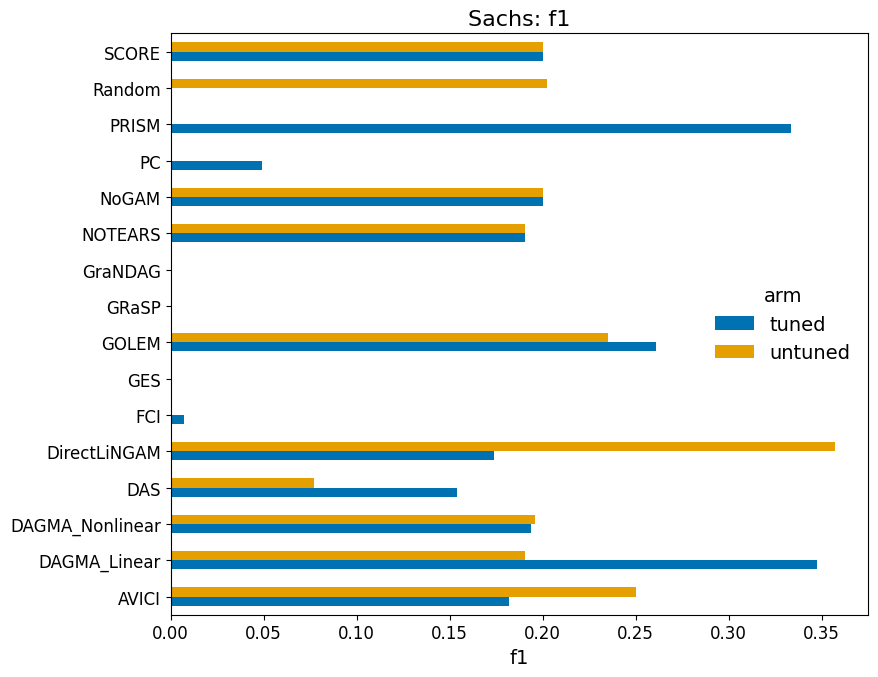

,base,arm,mean,std,size
0,AVICI,tuned,0.270270,0.000000,15
1,AVICI,untuned,0.333333,0.000000,15
2,DAGMA_Linear,tuned,0.487805,0.000000,15
3,DAGMA_Linear,untuned,0.303030,0.000000,15
4,DAGMA_Nonlinear,tuned,0.250215,0.097246,15
5,DAGMA_Nonlinear,untuned,0.295693,0.104384,15
6,DAS,tuned,0.188679,0.000000,15
7,DAS,untuned,0.094340,0.000000,15
8,DirectLiNGAM,tuned,0.243902,0.000000,15
9,DirectLiNGAM,untuned,0.409836,0.000000,15


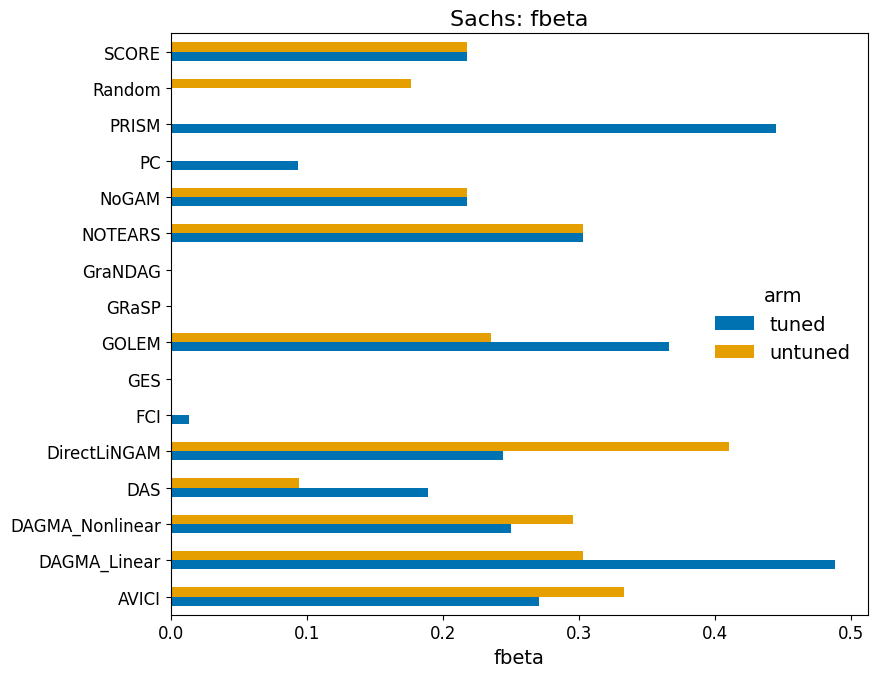

,base,arm,mean,std,size
0,AVICI,tuned,0.400000,0.000000,15
1,AVICI,untuned,0.428571,0.000000,15
2,DAGMA_Linear,tuned,0.666667,0.000000,15
3,DAGMA_Linear,untuned,0.500000,0.000000,15
4,DAGMA_Nonlinear,tuned,0.311640,0.112912,15
5,DAGMA_Nonlinear,untuned,0.451111,0.165767,15
6,DAS,tuned,0.222222,0.000000,15
7,DAS,untuned,0.111111,0.000000,15
8,DirectLiNGAM,tuned,0.333333,0.000000,15
9,DirectLiNGAM,untuned,0.454545,0.000000,15


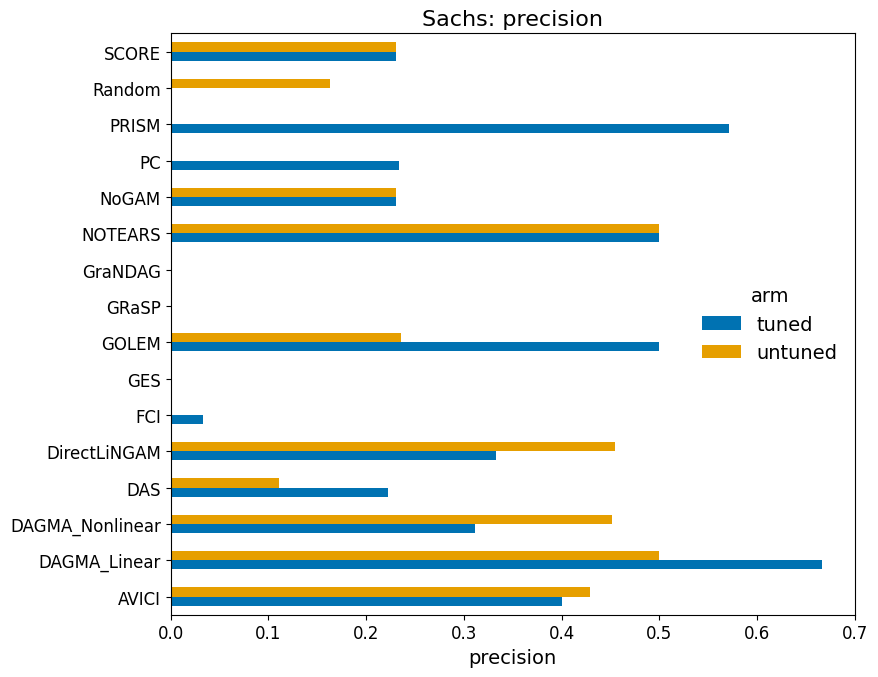

,base,arm,mean,std,size
0,AVICI,tuned,0.117647,0.000000,15
1,AVICI,untuned,0.176471,0.000000,15
2,DAGMA_Linear,tuned,0.235294,0.000000,15
3,DAGMA_Linear,untuned,0.117647,0.000000,15
4,DAGMA_Nonlinear,tuned,0.141176,0.062094,15
5,DAGMA_Nonlinear,untuned,0.125490,0.043719,15
6,DAS,tuned,0.117647,0.000000,15
7,DAS,untuned,0.058824,0.000000,15
8,DirectLiNGAM,tuned,0.117647,0.000000,15
9,DirectLiNGAM,untuned,0.294118,0.000000,15


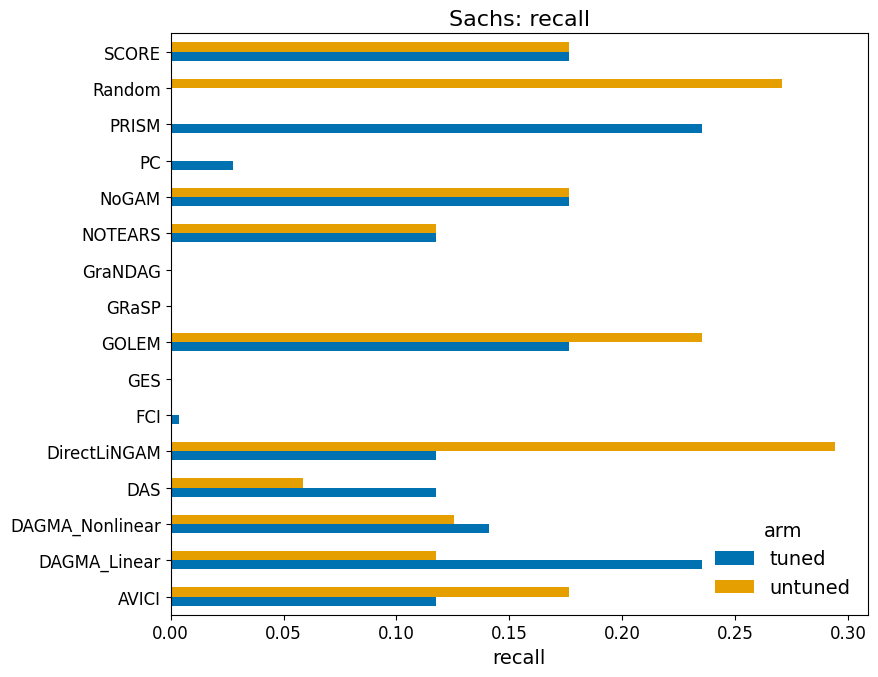

,base,arm,mean,std,size
0,AVICI,tuned,15.000000,0.000000,15
1,AVICI,untuned,15.000000,0.000000,15
2,DAGMA_Linear,tuned,13.000000,0.000000,15
3,DAGMA_Linear,untuned,15.000000,0.000000,15
4,DAGMA_Nonlinear,tuned,15.200000,0.861892,15
5,DAGMA_Nonlinear,untuned,14.866667,0.743223,15
6,DAS,tuned,16.000000,0.000000,15
7,DAS,untuned,18.000000,0.000000,15
8,DirectLiNGAM,tuned,15.000000,0.000000,15
9,DirectLiNGAM,untuned,14.000000,0.000000,15


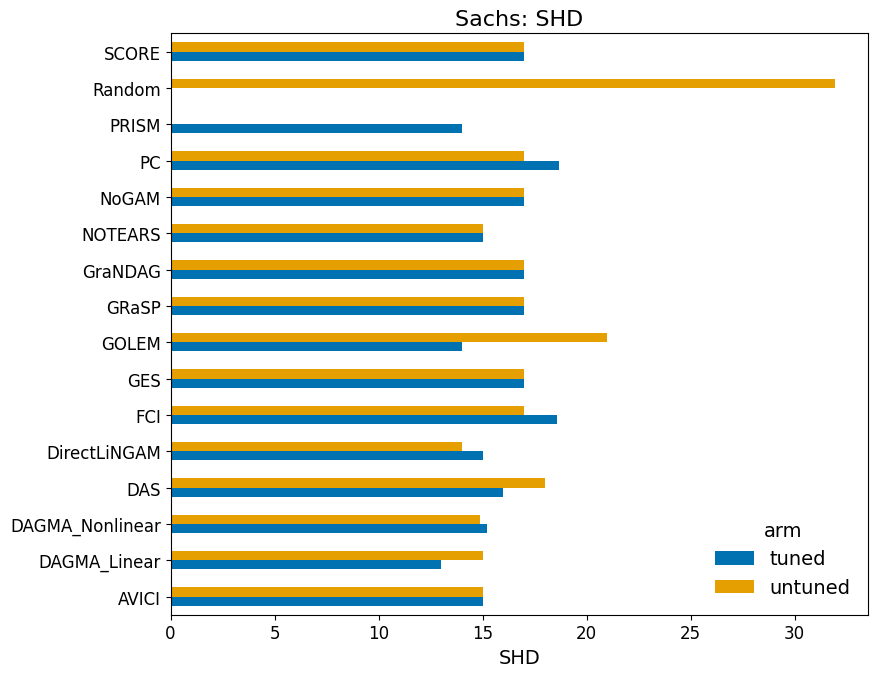

In [2]:
runs = sachs_table.load()
for metric in ("f1", "fbeta", "precision", "recall", "SHD"):
    summary = runs.groupby(["base", "arm"])[metric].agg(["mean", "std", "size"]).reset_index()
    display(summary.head(20))
    wide = summary.pivot(index="base", columns="arm", values="mean")
    ax = wide.plot.barh(figsize=(9, 7), title=f"Sachs: {metric}")
    ax.set(xlabel=metric, ylabel="")
    ax.figure.tight_layout()
    ax.figure.savefig(th.OUTPUT / f"sachs_{metric}.pdf")
    display(ax.figure)
    plt.close(ax.figure)
